# MileStone 2 Project: Decomposing Paired-Rating Disagreement
## Part A: Supervised Learning
1. Create seven disagreement outcomes.
2. Define predictor feature families.
3. Prepare training data; Preprocessing for training only.
4. Develop and compare Logistic Regression, Random Forest, and Gradient Boosting:
    - including TF-IDF-only and structured+TF-IDF Logistic Regression comparisons.
5. Select the best training-data configuration for each outcome and perform hyperparameter tuning.
6. Evaluate generalization within the training sample:
   - Primary: GroupKFold by unordered rater pair.
   - Secondary: GroupKFold by prompt.
7. Evaluate the frozen models with the 2,330 holdout cases.

## Part A2: Post-Hoc Supervised Model Evaluation
1. Use **permutation importance** to compare predictor importance consistently across models
2. Conduct **feature-family ablation** analysis to examine how predictive
   performance changes when individual predictor families are removed.
3. Conduct **hyperparameter-sensitivity** analysis to assess
   whether the findings are stable across reasonable parameter settings.
4. Examine **classification-threshold tradeoffs** using
   sensitivity, specificity, precision, F1, and balanced accuracy.
5. Conduct **failure analysis** using
   selected false-positive, false-negative, and borderline cases to characterize situations
   in which the model performs poorly.

## Part A2 should be used for diagnostic and explanatory purposes. 
1. These analyses are used to interpret the frozen supervised models,
   assess their robustness, and identify their limitations..
2. They are not used to revise or reselect the models after holdout evaluation.

# Part A — Supervised Learning Analysis

## 0. Load the Original Data
- The original data file contains a column, **set** which defines the training and test split.
- The dataset is divided into 3,510 training cases and 2,330 test cases.

In [1]:
# 0.1 Read in packages
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, precision_recall_curve, auc,
    balanced_accuracy_score, f1_score, confusion_matrix,
    silhouette_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

RANDOM_STATE = 589  # For the purpose of reproducibility
N_JOBS = -1         # Use all available CPU cores

In [2]:
# Creating results drive
RESULTS_DIR = Path('C:/Users/USEO9DA/0_MyStuff/M2/results')
# Read-in data file
DATA_PATH = Path(r'C:\Users\USEO9DA\0_MyStuff\M2\Data\0922_Final_Clean_Merged.csv')

# 0.2 Use original train / test split using the colomn, set
SET_COL = 'set'
TRAIN_LABEL = 'train'
HOLDOUT_LABEL = 'test'

# Loading the dataset based on file type
def read_table(path):
    suffix = path.suffix.lower()
    if suffix == '.csv':
        return pd.read_csv(path)
    if suffix in {'.xlsx', '.xls'}:
        return pd.read_excel(path)
    raise ValueError(f'Unsupported file type: {path.suffix}')
df = read_table(DATA_PATH)

# Standardizing the split labels for matching
split_values = (df[SET_COL].astype(str).str.strip().str.lower())

# Defining train and holdhout/test data
train_df = (df[split_values == TRAIN_LABEL.lower()].copy())
holdout_df = (df[split_values == HOLDOUT_LABEL.lower()].copy())
print('Full sample :', df.shape)
print('Training    :', train_df.shape)
print('Holdout     :', holdout_df.shape)

Full sample : (5840, 75)
Training    : (3510, 75)
Holdout     : (2330, 75)


## Stage 1: Create the Seven Disagreement Uutcomes
- For each dimension: `Y_d = 1` when `Delta_d > 0`, otherwise `0`.

In [3]:
# Seven Dimensions as Ys
DIMS = ['Overall','Cohesion','Syntax','Vocabulary','Phraseology','Grammar','Conventions']

# Checking whether all required paired-rating columns are present.
required = [f'{d}_{r}' for d in DIMS for r in (1,2)]
missing = [c for c in required if c not in train_df.columns]
if missing:
    raise ValueError(f'Missing rating columns: {missing}')

# Creating absolute disagreement scores and binary disagreement outcomes
def add_disagreement_outcomes(data):
    out = data.copy()
    for d in DIMS:
        out[f'Delta_{d}'] = (out[f'{d}_2'] - out[f'{d}_1']).abs()
        out[f'Y_{d}'] = (out[f'Delta_{d}'] > 0).astype(int)
    return out
train_df = add_disagreement_outcomes(train_df) # Train data
holdout_df = add_disagreement_outcomes(holdout_df) # Test data

DELTA_COLS = [f'Delta_{d}' for d in DIMS] # Create column-name lists for all seven scoring dimensions.
TARGET_COLS = [f'Y_{d}' for d in DIMS]    # TARGET_COLS: Binary disagreement outcomes

summary = []
for d in DIMS:
    y = train_df[f'Y_{d}']
    summary.append({
        'dimension': d,
        'total_n': len(y),
        'agreement_n': int((y==0).sum()),
        'disagreement_n': int((y==1).sum()),
        'disagreement_rate': y.mean(),
        'mean_abs_difference': train_df[f'Delta_{d}'].mean()})
train_rater_disagreement_summary = pd.DataFrame(summary)

# Displaying the summary
display(train_rater_disagreement_summary)

# Saving the summary results
output_file = RESULTS_DIR / 'train_rater_disagreement_summary.csv'
train_rater_disagreement_summary.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

,dimension,total_n,agreement_n,disagreement_n,disagreement_rate,mean_abs_difference
0,Overall,3510,2128,1382,0.393732,0.394017
1,Cohesion,3510,1760,1750,0.498575,0.510256
2,Syntax,3510,1869,1641,0.467521,0.470655
3,Vocabulary,3510,2023,1487,0.423647,0.426496
4,Phraseology,3510,1887,1623,0.462393,0.467521
5,Grammar,3510,1810,1700,0.484330,0.492877
6,Conventions,3510,1881,1629,0.464103,0.471225


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\train_rater_disagreement_summary.csv


## Stage 2: Define Feature Families as Predictor
#### Core Feature Families:
1. Assessment context: prompt, grade;
2. Structured linguistic/writing: word count, sentence count, paragraph count, MTLD, TTR;
3. Student background: gender, race/ethnicity, SES;
4. Rater context: Rater_1, Rater_2;
5. Word TF-IDF

In [4]:
# Defined feature families from the data file
FEATURE_FAMILIES = {'assessment_context': ['prompt','grade'],
    'linguistic_writing': ['num_words','num_sent','num_para','MTLD','TTR'],
    'student_background': ['gender','race_ethnicity','SES'],
    'rater_context': ['Rater_1','Rater_2'],}
TEXT_COL = 'QA_Full_Text_main'

PROHIBITED = set(DIMS)
for d in DIMS:
    PROHIBITED |= {f'{d}_1', f'{d}_2', f'Delta_{d}', f'Y_{d}'}

all_core = [c for cols in FEATURE_FAMILIES.values() for c in cols]
leak = sorted(set(all_core) & PROHIBITED)
if leak:
    raise ValueError(f'Target leakage detected: {leak}')

for fam, cols in FEATURE_FAMILIES.items():
    print(fam, '->', cols)

assessment_context -> ['prompt', 'grade']
linguistic_writing -> ['num_words', 'num_sent', 'num_para', 'MTLD', 'TTR']
student_background -> ['gender', 'race_ethnicity', 'SES']
rater_context -> ['Rater_1', 'Rater_2']


## Stage 3: Prepare Training Data for Modeling
- All imputation, scaling, and encoding are fitted inside the training folds.
- The holdout data are not used to learn preprocessing.

In [5]:
# Identifying numeric and categorical predictors 
NUMERIC = ['num_words','num_sent','num_para','MTLD','TTR']
CATEGORICAL = ['prompt','grade','gender','race_ethnicity','SES','Rater_1','Rater_2']

# Creating a version-compatible one-hot encoder that safely handles unseen categories
def make_ohe(dense=True):
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=not dense)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=not dense)

# Building preprocessing for the selected feature set:
# impute/scale numeric variables and impute/one-hot encode categorical variables
def build_preprocessor(feature_cols):
    numeric_cols = [c for c in feature_cols if c in NUMERIC]
    categorical_cols = [c for c in feature_cols if c in CATEGORICAL]
    blocks = []
    if numeric_cols:
        blocks.append(('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())]), numeric_cols))
    if categorical_cols:
        blocks.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', make_ohe(dense=True))]), categorical_cols))
    return ColumnTransformer(blocks, remainder='drop', verbose_feature_names_out=False)

# Defining feature sets for comparing different predictor combinations
FEATURE_SETS = {'context_only': FEATURE_FAMILIES['assessment_context'],
    'linguistic_only': FEATURE_FAMILIES['linguistic_writing'],
    'student_only': FEATURE_FAMILIES['student_background'],
    'rater_only': FEATURE_FAMILIES['rater_context'],
    # Defining the feature sets used to compare different predictor combinations
    'context_plus_linguistic': FEATURE_FAMILIES['assessment_context'] + FEATURE_FAMILIES['linguistic_writing'],
    'all_structured': sum(FEATURE_FAMILIES.values(), []),}

## Stage 3A: Creating and Adding Word-Level TF-IDF
- Word-level TF-IDF is included as a primary text representation.
- The TF-IDF vocabulary is learned within each training fold to prevent data leakage.
- Formal TF-IDF model comparisons are conducted in Stage 4 for all seven disagreement outcomes.

In [6]:
# Defining fixed settings for the word-level TF-IDF representation
TFIDF_KWARGS = {
    'min_df': 3,            # Keep terms that appear in at least 3 essays
    'max_df': 0.95,         # Remove terms that appear in more than 95% of essays
    'ngram_range': (1, 2),  # Use single words and two-word phrases
    'max_features': 5000,   # Keep up to 5,000 TF-IDF features
    'sublinear_tf': True,   # Reduce the effect of repeated words within an essay
}

# Building the structured + TF-IDF Logistic Regression pipeline
    # Numeric, categorical, and text features are preprocessed and then combined.
def text_plus_structured_logistic(feature_cols):
    numeric_cols = [c for c in feature_cols if c in NUMERIC]
    categorical_cols = [c for c in feature_cols if c in CATEGORICAL]
    blocks = []
    if numeric_cols:
        blocks.append(('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols))
    if categorical_cols:
        blocks.append(('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            # Using a sparse one-hot representation due to sparse TF-IDF itself
            ('onehot', make_ohe(dense=False))
        ]), categorical_cols))

    # Adding the essay text representation to the structured predictors
    blocks.append(('tfidf', TfidfVectorizer(**TFIDF_KWARGS), TEXT_COL)) 

    # Combining all preprocessing blocks into one sparse feature matrix
    pre = ColumnTransformer(blocks, sparse_threshold=1.0) # Keeping the combined output sparse whenever possible

    return Pipeline([('preprocess', pre),
        ('model', LogisticRegression(
            max_iter=5000,
            class_weight='balanced',
            # Logistic Regression with saga for large sparse feature matrices, TF-IDF.
            solver='saga',
            random_state=RANDOM_STATE))])

# Selecting the correct structured and/or text predictors for each model configuration
def configuration_input(data, feature_set_name):
    if feature_set_name == 'tfidf_only':
        X = data[[TEXT_COL]].copy()
        X[TEXT_COL] = X[TEXT_COL].fillna('').astype(str)
        return X
    if feature_set_name == 'all_structured_plus_tfidf':
        cols = FEATURE_SETS['all_structured']
        X = data[cols + [TEXT_COL]].copy()
        X[TEXT_COL] = X[TEXT_COL].fillna('').astype(str)
        return X
    if feature_set_name not in FEATURE_SETS:
        raise ValueError(f'Unknown feature set: {feature_set_name}')
    return data[FEATURE_SETS[feature_set_name]].copy()


# Building the appropriate preprocessing + model pipeline for each Stage 4 configuration.
def build_configuration_pipeline(feature_set_name, model_name):
    if feature_set_name == 'tfidf_only':
        if model_name != 'logistic_regression':
            raise ValueError('TF-IDF-only is evaluated with logistic regression.')
        return text_plus_structured_logistic([])
    if feature_set_name == 'all_structured_plus_tfidf':
        if model_name != 'logistic_regression':
            raise ValueError('Structured + TF-IDF is evaluated with logistic regression.')
        return text_plus_structured_logistic(FEATURE_SETS['all_structured'])
    if feature_set_name not in FEATURE_SETS:
        raise ValueError(f'Unknown feature set: {feature_set_name}')
    cols = FEATURE_SETS[feature_set_name]
    return Pipeline([('preprocess', build_preprocessor(cols)),('model', clone(MODELS[model_name]))])

## Stage 4: Develop and Compare Supervised Models
- **A 5-fold stratified cross-validation procedure** was used on the training cases to preserve agreement/disagreement proportions within each outcome.
- Because the seven outcomes have different class distributions, their fold assignments may differ slightly;
- However, all competing models for the same outcome.
- Use the same CV setup.
## Formal Comparison Includes:
1. Structured feature sets with Logistic Regression, Random Forest, and Gradient Boosting;
2. Word TF-IDF only + Logistic Regression; and
3. All structured features + word TF-IDF + Logistic Regression.
4. **Reason for including TF-IDF (#2 and #3)**: To evaluate whether essay text alone predicts disagreement and whether adding essay text improves prediction beyond the structured features.

In [7]:
# Defining the three machine-learning algorithms to compare
MODELS = {'logistic_regression': LogisticRegression(
        max_iter=5000,
        class_weight='balanced',
        random_state=RANDOM_STATE),
    'random_forest': RandomForestClassifier(
        n_estimators=500,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS),
    'gradient_boosting': GradientBoostingClassifier(
        random_state=RANDOM_STATE),}

# Conditions to divide the training data into 5 stratified folds for model comparison
    # n-splits: divide the training data into 5 folds
    # shuffle: mix the essays before creating the folds
    # stratifiedKFold: keep the agreement/disagreement proportions roughly similar in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Evaluating each model using different classification metrics
    # ROC-AUC is primary metric for model selection
SCORING = {'roc_auc': 'roc_auc','average_precision': 'average_precision','balanced_accuracy': 'balanced_accuracy',
    'f1': 'f1','sensitivity': 'recall',}

# Summarizing each model's 5-fold CV performance using the mean and standard deviation of each metric
def summarize_cv_scores(target_col, feature_set_name, model_name, sc):
    row = {'target': target_col,'feature_set': feature_set_name,'model': model_name,}
    for m in ['roc_auc', 'average_precision', 'balanced_accuracy', 'f1', 'sensitivity']:
        row[f'{m}_mean'] = sc[f'test_{m}'].mean()
        row[f'{m}_sd'] = sc[f'test_{m}'].std(ddof=1)
    return row

# Comparing all model configurations for one outcome using 5-fold stratified cross-validation
def run_cv_comparison(data, target_col):
    rows = []
    y = data[target_col].astype(int)
    # A. Structured-feature comparisons: LR, RF, and GB
    for fs_name in FEATURE_SETS:
        X = configuration_input(data, fs_name)
        for model_name in MODELS:
            pipe = build_configuration_pipeline(fs_name, model_name)
            sc = cross_validate(pipe,X,y,cv=cv,n_jobs=N_JOBS,scoring=SCORING)
            rows.append(summarize_cv_scores(target_col,fs_name,model_name,sc))

    # B. Text comparison 1: word TF-IDF only + Logistic Regression
    fs_name = 'tfidf_only'
    model_name = 'logistic_regression'
    X = configuration_input(data, fs_name)
    pipe = build_configuration_pipeline(fs_name, model_name)
    sc = cross_validate(pipe,X,y,cv=cv,n_jobs=N_JOBS,scoring=SCORING)
    rows.append(summarize_cv_scores(target_col,fs_name,model_name,sc))

    # C. Text comparison 2: all structured + word TF-IDF + Logistic Regression
    fs_name = 'all_structured_plus_tfidf'
    model_name = 'logistic_regression'
    X = configuration_input(data, fs_name)
    pipe = build_configuration_pipeline(fs_name, model_name)
    sc = cross_validate(pipe,X,y,cv=cv,n_jobs=N_JOBS,scoring=SCORING)
    rows.append(summarize_cv_scores(target_col, fs_name, model_name, sc))
    return pd.DataFrame(rows)

# Running the model comparison for all seven outcomes and combining the results into one table
all_cv = []
for target in TARGET_COLS:
    print('Running', target)
    all_cv.append(run_cv_comparison(train_df, target))
cv_diagreement_results = pd.concat(all_cv, ignore_index=True)

# Sorting the results
cv_diagreement_results_sorted = cv_diagreement_results.sort_values(['target', 'roc_auc_mean'],ascending=[True, False])

# Displaying the results
display(cv_diagreement_results_sorted)

# Saving the results
output_file = RESULTS_DIR / 'cv_diagreement_results.csv'
cv_diagreement_results_sorted.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Running Y_Overall
Running Y_Cohesion
Running Y_Syntax
Running Y_Vocabulary
Running Y_Phraseology
Running Y_Grammar
Running Y_Conventions


,target,feature_set,model,roc_auc_mean,roc_auc_sd,average_precision_mean,average_precision_sd,balanced_accuracy_mean,balanced_accuracy_sd,f1_mean,f1_sd,sensitivity_mean,sensitivity_sd
30,Y_Cohesion,rater_only,random_forest,0.553099,0.017040,0.541648,0.011366,0.540877,0.016152,0.514682,0.022386,0.488571,0.027701
29,Y_Cohesion,rater_only,logistic_regression,0.552383,0.020235,0.543251,0.017207,0.548545,0.017199,0.518384,0.025131,0.488000,0.036276
31,Y_Cohesion,rater_only,gradient_boosting,0.552290,0.021207,0.539979,0.016072,0.544808,0.023770,0.508394,0.030159,0.472571,0.037558
39,Y_Cohesion,all_structured_plus_tfidf,logistic_regression,0.541430,0.013742,0.539853,0.018405,0.530182,0.013226,0.526315,0.015333,0.524000,0.029039
35,Y_Cohesion,all_structured,logistic_regression,0.539019,0.022325,0.539742,0.024046,0.533284,0.021354,0.523976,0.028199,0.516000,0.038998
...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,Y_Vocabulary,student_only,gradient_boosting,0.499552,0.026110,0.428015,0.019365,0.491760,0.012302,0.054332,0.037929,0.030949,0.023263
67,Y_Vocabulary,student_only,random_forest,0.498871,0.025217,0.427480,0.020646,0.495542,0.018182,0.378875,0.068567,0.361806,0.119530
78,Y_Vocabulary,tfidf_only,logistic_regression,0.498070,0.014043,0.419996,0.007493,0.503550,0.019444,0.440383,0.018555,0.453960,0.019470
63,Y_Vocabulary,linguistic_only,logistic_regression,0.493166,0.016466,0.422080,0.010055,0.490692,0.018861,0.474466,0.016162,0.552781,0.023047


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\cv_diagreement_results.csv


## Stage 4.1: Overall Model-Family Comparison
- This cell directly addresses the requirement to compare the best result from each supervised model family - using **multiple CV folds**.
- For every disagreement outcome and each model family, it selects the feature representation with the highest mean training-CV ROC-AUC and reports **mean ± SD**.
- Selection here uses only the existing training CV results in `cv_diagreement_results`.

In [8]:
# For Report Purpose: Best Result form each model family
    # 5-fold CV ROC-AUC mean ± SD
required_columns = ['target','feature_set','model','roc_auc_mean','roc_auc_sd']
missing = [c for c in required_columns if c not in cv_diagreement_results.columns]
if missing:
    raise ValueError(f'cv_diagreement_results is missing required columns: {missing}')

# Selecting the strongest feature representation within each model family
    # for each of the seven outcomes.
best_family_idx = (cv_diagreement_results.groupby(['target', 'model'])['roc_auc_mean'].idxmax())
best_by_model_family = (cv_diagreement_results.loc[best_family_idx].copy().sort_values(['target', 'model']).reset_index(drop=True))
best_by_model_family['ROC_AUC_Mean_SD'] = (best_by_model_family.apply(
        lambda r: f"{r['roc_auc_mean']:.3f} ± {r['roc_auc_sd']:.3f}",
        axis=1))
family_diagreement_long = best_by_model_family[
    ['target','model','feature_set','roc_auc_mean','roc_auc_sd','ROC_AUC_Mean_SD']].copy()

print('=' * 70)
print('Best Feature Representation within Each Model Family')
print('5-FOLD CV — ROC-AUC MEAN ± SD')
print('=' * 70)
display(family_diagreement_long)

# Compacting the report table: 7 outcomes × 3 algorithm families.
family_diagreement_compact = (family_diagreement_long.assign(result=(
            family_diagreement_long['ROC_AUC_Mean_SD']+'['+family_diagreement_long['feature_set']+']')).pivot(index='target',columns='model',values='result'))

print('=' * 70)
print('Report-Ready Model-Family Comparison')
print('=' * 70)
display(family_diagreement_compact)

# Saving family long summary
output_file = RESULTS_DIR / 'family_diagreement_long.csv'
family_diagreement_long.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

# Saving family compact summary
output_file = RESULTS_DIR / 'family_diagreement_compact.csv'
family_diagreement_compact.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Best Feature Representation within Each Model Family
5-FOLD CV — ROC-AUC MEAN ± SD


,target,model,feature_set,roc_auc_mean,roc_auc_sd,ROC_AUC_Mean_SD
0,Y_Cohesion,gradient_boosting,rater_only,0.552290,0.021207,0.552 ± 0.021
1,Y_Cohesion,logistic_regression,rater_only,0.552383,0.020235,0.552 ± 0.020
2,Y_Cohesion,random_forest,rater_only,0.553099,0.017040,0.553 ± 0.017
3,Y_Conventions,gradient_boosting,rater_only,0.531371,0.015381,0.531 ± 0.015
4,Y_Conventions,logistic_regression,rater_only,0.527151,0.010563,0.527 ± 0.011
5,Y_Conventions,random_forest,rater_only,0.533474,0.015721,0.533 ± 0.016
6,Y_Grammar,gradient_boosting,rater_only,0.548474,0.012975,0.548 ± 0.013
7,Y_Grammar,logistic_regression,all_structured,0.539691,0.022019,0.540 ± 0.022
8,Y_Grammar,random_forest,rater_only,0.535576,0.010852,0.536 ± 0.011
9,Y_Overall,gradient_boosting,rater_only,0.537701,0.011228,0.538 ± 0.011


Report-Ready Model-Family Comparison


model,gradient_boosting,logistic_regression,random_forest
target,,,
Y_Cohesion,0.552 ± 0.021[rater_only],0.552 ± 0.020[rater_only],0.553 ± 0.017[rater_only]
Y_Conventions,0.531 ± 0.015[rater_only],0.527 ± 0.011[rater_only],0.533 ± 0.016[rater_only]
Y_Grammar,0.548 ± 0.013[rater_only],0.540 ± 0.022[all_structured],0.536 ± 0.011[rater_only]
Y_Overall,0.538 ± 0.011[rater_only],0.533 ± 0.020[all_structured],0.536 ± 0.010[rater_only]
Y_Phraseology,0.537 ± 0.019[all_structured],0.537 ± 0.015[rater_only],0.529 ± 0.012[rater_only]
Y_Syntax,0.534 ± 0.022[rater_only],0.525 ± 0.019[all_structured],0.533 ± 0.008[all_structured]
Y_Vocabulary,0.527 ± 0.022[rater_only],0.529 ± 0.023[rater_only],0.536 ± 0.029[rater_only]


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\family_diagreement_long.csv
Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\family_diagreement_compact.csv


## Stage 4.2: Feature-Representation Comparison

- The original Stage 4 analysis already compared the feature representations.
- The following cell reorganizes those existing results
- For each outcome and representation, the strongest algorithm is shown with its 5-fold CV mean and SD.
- This is a **reporting transformation**, not a new model-selection stage.

In [9]:
# For Final Report Purpose: Feaure Representation Comparison 
best_rep_idx = (cv_diagreement_results.groupby(['target', 'feature_set'])['roc_auc_mean'].idxmax())
best_by_representation = (cv_diagreement_results.loc[best_rep_idx].copy().sort_values(['target', 'roc_auc_mean'],ascending=[True, False]).reset_index(drop=True))
best_by_representation['ROC_AUC_Mean_SD'] = (best_by_representation.apply(lambda r: f"{r['roc_auc_mean']:.3f} ± {r['roc_auc_sd']:.3f}",axis=1))
rater_representation_table = best_by_representation[
    ['target','feature_set','model','roc_auc_mean','roc_auc_sd','ROC_AUC_Mean_SD']].copy()

print('=' * 70)
print('Final Report: Rater Feature-Representation Comparison')
print('=' * 70)
display(rater_representation_table)

# Save family compact summary
output_file = RESULTS_DIR / 'final_report_feature_representation_comparison.csv'
rater_representation_table.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Final Report: Rater Feature-Representation Comparison


,target,feature_set,model,roc_auc_mean,roc_auc_sd,ROC_AUC_Mean_SD
0,Y_Cohesion,rater_only,random_forest,0.553099,0.017040,0.553 ± 0.017
1,Y_Cohesion,all_structured_plus_tfidf,logistic_regression,0.541430,0.013742,0.541 ± 0.014
2,Y_Cohesion,all_structured,logistic_regression,0.539019,0.022325,0.539 ± 0.022
3,Y_Cohesion,linguistic_only,logistic_regression,0.518727,0.017956,0.519 ± 0.018
4,Y_Cohesion,context_only,random_forest,0.516991,0.013492,0.517 ± 0.013
5,Y_Cohesion,tfidf_only,logistic_regression,0.515958,0.015011,0.516 ± 0.015
6,Y_Cohesion,context_plus_linguistic,logistic_regression,0.508646,0.016294,0.509 ± 0.016
7,Y_Cohesion,student_only,random_forest,0.484407,0.011766,0.484 ± 0.012
8,Y_Conventions,rater_only,random_forest,0.533474,0.015721,0.533 ± 0.016
9,Y_Conventions,all_structured,gradient_boosting,0.514311,0.019401,0.514 ± 0.019


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_feature_representation_comparison.csv


## Stage 4.3: Best Configuration for Each Outcome
- Select the best model + feature set for each of the seven outcomes.
- Use the highest mean 5-fold CV ROC-AUC.
- Advance selected configurations to Stage 5 tuning.

In [10]:
# For Final Report Purpose: Identifing the row with the highest mean CV ROC-AUC 
    # for each of the seven disagreement outcomes
best_overall_idx = (cv_diagreement_results.groupby('target')['roc_auc_mean'].idxmax())

# Creating a report-ready table of the seven selected configurations.
selected_config_table = (cv_diagreement_results.loc[best_overall_idx,['target','feature_set','model','roc_auc_mean','roc_auc_sd']].copy().sort_values('target').reset_index(drop=True))

# Formating ROC-AUC mean ± SD for reporting.
selected_config_table['ROC_AUC_Mean_SD'] = (selected_config_table.apply(lambda r: (f"{r['roc_auc_mean']:.3f} ± "f"{r['roc_auc_sd']:.3f}"),axis=1))

print('=' * 70)
print('Selected Best Configuration for Each Outcome')
print('Highest Mean 5-Fold CV ROC-AUC')
print('=' * 70)

display(selected_config_table)

# Save family compact summary
output_file = RESULTS_DIR / 'stage4_rater_selected_best_configurations.csv'
selected_config_table.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

# Create Seleted Configures for Stage 5 tuning below
SELECTED_CONFIGS = {
    row['target']: {
        'feature_set': row['feature_set'],
        'model': row['model'],
        'initial_roc_auc': row['roc_auc_mean']
    }
    for _, row in selected_config_table.iterrows()
}

print('\nSelected Configurations')
print('=' * 70)

for target, config in SELECTED_CONFIGS.items():
    print(
        f"{target}: "
        f"{config['feature_set']} + "
        f"{config['model']} "
        f"(CV ROC-AUC = {config['initial_roc_auc']:.6f})"
    )

Selected Best Configuration for Each Outcome
Highest Mean 5-Fold CV ROC-AUC


,target,feature_set,model,roc_auc_mean,roc_auc_sd,ROC_AUC_Mean_SD
0,Y_Cohesion,rater_only,random_forest,0.553099,0.017040,0.553 ± 0.017
1,Y_Conventions,rater_only,random_forest,0.533474,0.015721,0.533 ± 0.016
2,Y_Grammar,rater_only,gradient_boosting,0.548474,0.012975,0.548 ± 0.013
3,Y_Overall,rater_only,gradient_boosting,0.537701,0.011228,0.538 ± 0.011
4,Y_Phraseology,rater_only,logistic_regression,0.536776,0.015444,0.537 ± 0.015
5,Y_Syntax,rater_only,gradient_boosting,0.533887,0.022100,0.534 ± 0.022
6,Y_Vocabulary,rater_only,random_forest,0.535624,0.029096,0.536 ± 0.029


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\stage4_rater_selected_best_configurations.csv

Selected Configurations
Y_Cohesion: rater_only + random_forest (CV ROC-AUC = 0.553099)
Y_Conventions: rater_only + random_forest (CV ROC-AUC = 0.533474)
Y_Grammar: rater_only + gradient_boosting (CV ROC-AUC = 0.548474)
Y_Overall: rater_only + gradient_boosting (CV ROC-AUC = 0.537701)
Y_Phraseology: rater_only + logistic_regression (CV ROC-AUC = 0.536776)
Y_Syntax: rater_only + gradient_boosting (CV ROC-AUC = 0.533887)
Y_Vocabulary: rater_only + random_forest (CV ROC-AUC = 0.535624)


## Stage 5: Tune Selected Configurations
- Based on the Stage 4 cross-validation results above, tune the highest-performing configuration for each disagreement outcome using the same primary scoring metric, mean 5-fold CV ROC-AUC. 
- Because TF-IDF was not selected as the best configuration for any outcome, TF-IDF models are not tuned in this stage.

### Hyperparameter tuning rules of selected best configurations
1. Primary metric: highest mean ROC-AUC across 5 CV folds.
2. Configuration selection:
    1) Select the highest mean 5-fold CV ROC-AUC, then tune it.
    2) rater_only was best for all seven outcomes; the best algorithm varied
3. TF-IDF:
    1) As said earlier, it was included in the preliminary model comparison, 
    2) but **NOT fine-tuned** because it was not selected as best for any outcome.
4. Tuned 5-fold CV score:
    1) **search.best_score_** is the best average ROC-AUC across the 5 tuning folds

In [11]:
# ROC-AUC used to select the best tuning result
PRIMARY_SCORING = 'roc_auc'

# Hyperparameter grids:
    # Moderate grids are used to tune only the configurations
    # Selected in Stage 4 while limiting unnecessary search.
PARAM_GRIDS = {
    'logistic_regression': {
        'model__C': [0.01, 0.1, 1, 10]
    },

    'random_forest': {
        'model__n_estimators': [300, 500],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_leaf': [1, 2, 5],
        'model__max_features': ['sqrt', 0.5],
    },

    'gradient_boosting': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_depth': [2, 3],
        'model__subsample': [0.8, 1.0],
    },
}

# Tuning cross-validation:
    # 1. Use the same 5-fold stratified cross-validation used in the preliminary model comparison.
    # 2. Stratification preserves outcome class proportions, but rater pairs may appear in both training and validation folds.
    # 3. Rater-pair GroupKFold is conducted separately as the primary robustness analysis.

# Tuning the selected configuration
TUNING_CV = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)


# Tuning function
def tune_configuration(data,target_col,feature_set_name,model_name):
    # Construct the input required for the selected configuration.
    X = configuration_input(data,feature_set_name)
    y = data[target_col].astype(int)

    # Build the complete modeling pipeline.
    pipe = build_configuration_pipeline(feature_set_name,model_name)

    search = GridSearchCV(estimator=pipe,param_grid=PARAM_GRIDS[model_name],        
        scoring=PRIMARY_SCORING, # Prespecified primary selection metric        
        cv=TUNING_CV, # Training-data CV only
        n_jobs=N_JOBS,       
        refit=True,  # After CV, refit the best hyperparameter configuration on the full training sample
        return_train_score=False
    )
    search.fit(X, y)
    return search

# Run tuning for all seven disagreement outcomes
tuned_searches = {}
tuning_rows = []
for target, config in SELECTED_CONFIGS.items():
    feature_set = config['feature_set']
    model_name = config['model']
    print("=" * 70)
    print(f"Tuning {target}: "f"{feature_set} + {model_name}")
    search = tune_configuration(train_df,target,feature_set,model_name)
    tuned_searches[target] = search     # Preserve the complete fitted search object.\
    tuning_rows.append({
        'target': target,
        'feature_set': feature_set,
        'model': model_name,        
        'initial_cv_roc_auc': config['initial_roc_auc'], # Mean ROC-AUC from the original model-comparison stage
        'tuned_cv_roc_auc': search.best_score_, # Highest mean CV ROC-AUC obtained during GridSearchCV
        # tuning improved generalization.
        'cv_auc_change':
            search.best_score_ - config['initial_roc_auc'],
        'best_params': search.best_params_
    })

    print("Best parameters:")
    print(search.best_params_)
    print(f"Initial CV ROC-AUC: "f"{config['initial_roc_auc']:.6f}")
    print(f"Best tuned CV ROC-AUC: "f"{search.best_score_:.6f}")
    print(f"Descriptive CV change: "f"{search.best_score_ - config['initial_roc_auc']:+.6f}")


# Tuning summary
tuning_disagreement_results = pd.DataFrame(tuning_rows)
tuning_disagreement_results_sorted = tuning_disagreement_results.sort_values(
    'tuned_cv_roc_auc',
    ascending=False
).reset_index(drop=True)

display(tuning_disagreement_results_sorted)

# Saving results
output_file = RESULTS_DIR / 'tuning_disagreement_results.csv'
tuning_disagreement_results_sorted.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Tuning Y_Cohesion: rater_only + random_forest
Best parameters:
{'model__max_depth': 10, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
Initial CV ROC-AUC: 0.553099
Best tuned CV ROC-AUC: 0.557011
Descriptive CV change: +0.003912
Tuning Y_Conventions: rater_only + random_forest
Best parameters:
{'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Initial CV ROC-AUC: 0.533474
Best tuned CV ROC-AUC: 0.534501
Descriptive CV change: +0.001027
Tuning Y_Grammar: rater_only + gradient_boosting
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}
Initial CV ROC-AUC: 0.548474
Best tuned CV ROC-AUC: 0.551012
Descriptive CV change: +0.002537
Tuning Y_Overall: rater_only + gradient_boosting
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 1.0}
Initial CV ROC-AUC: 0.5

,target,feature_set,model,initial_cv_roc_auc,tuned_cv_roc_auc,cv_auc_change,best_params
0,Y_Cohesion,rater_only,random_forest,0.553099,0.557011,0.003912,"{'model__max_depth': 10, 'model__max_features'..."
1,Y_Grammar,rater_only,gradient_boosting,0.548474,0.551012,0.002537,"{'model__learning_rate': 0.1, 'model__max_dept..."
2,Y_Phraseology,rater_only,logistic_regression,0.536776,0.540107,0.003331,{'model__C': 0.1}
3,Y_Syntax,rater_only,gradient_boosting,0.533887,0.538607,0.004719,"{'model__learning_rate': 0.03, 'model__max_dep..."
4,Y_Overall,rater_only,gradient_boosting,0.537701,0.537701,0.000000,"{'model__learning_rate': 0.1, 'model__max_dept..."
5,Y_Vocabulary,rater_only,random_forest,0.535624,0.536947,0.001324,"{'model__max_depth': 20, 'model__max_features'..."
6,Y_Conventions,rater_only,random_forest,0.533474,0.534501,0.001027,"{'model__max_depth': 20, 'model__max_features'..."


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\tuning_disagreement_results.csv


## Stage 6: Robustness Evaluation
#### Stage 6A: Robustness Evaluation — GroupKFold by unordered rater pair
- Rater-context models showed the strongest initial signal.
- This is the primary robustness analysis.
- `Rater_1` and `Rater_2` are collapsed into an **unordered rater-pair ID**.
- The same pair cannot appear in both the training and validation portions of a fold.
- This tests whether predictive performance generalizes beyond familiar rater-pair combinations.
#### Stage 6B: Robostsness Evaluation - GroupKFold-by-prompt 
- Conduct this analysis to test generalization to unseen prompts.

In [12]:
# 6A GroupKfold by Unordered Rater Pair
    # Purpose: Test whether the predictive signal generalizes to rater PAIRS
    # that were not represented in the corresponding training fold.

# Creating a single rater-pair label that ignores order
def make_unordered_rater_pair(data):
    r1 = data['Rater_1'].fillna('__MISSING__').astype(str)
    r2 = data['Rater_2'].fillna('__MISSING__').astype(str)
    pairs = [
        f'{a}||{b}' if a <= b else f'{b}||{a}'
        for a, b in zip(r1, r2)
    ]
    return pd.Series(pairs,index=data.index,name='rater_pair')

# Primary Robustness Evaluation
    # Test the tuned model with 5-fold GroupKFold by unordered rater pair
    # The exact same rater pair cannot appear in both training and validation.
def rater_pair_group_cv(data,target_col,feature_set_name,pipeline,n_splits=5):
    X = configuration_input(data,feature_set_name)
    y = data[target_col].astype(int)
    groups = make_unordered_rater_pair(data)
    n_pairs = groups.nunique()
    if n_pairs < n_splits:
        raise ValueError(
            f'Only {n_pairs} unique unordered rater pairs are available; '
            f'n_splits={n_splits} is too large.'
        )
    gkf = GroupKFold(n_splits=n_splits)
    rows = []
    for fold, (tr, va) in enumerate(
        gkf.split(X, y, groups),
        start=1
    ):        
        m = clone(pipeline) # Clone the already tuned estimator.
        m.fit(X.iloc[tr],y.iloc[tr])
        pred = m.predict(X.iloc[va])
        score = m.predict_proba(X.iloc[va])[:, 1]
        precision, recall, _ = precision_recall_curve(y.iloc[va],score) # Precision-recall curve
        tn, fp, fn, tp = confusion_matrix(y.iloc[va],pred,labels=[0, 1]).ravel() # Confusion matrix
        # Verify complete pair separation
        train_pairs = set(groups.iloc[tr])
        valid_pairs = set(groups.iloc[va])
        overlap = train_pairs & valid_pairs
        rows.append({
            'target': target_col,
            'feature_set': feature_set_name,
            'fold': fold,
            'n_train': len(tr),
            'n_valid': len(va),
            'n_train_rater_pairs': len(train_pairs),
            'n_valid_rater_pairs': len(valid_pairs),
            'rater_pair_overlap_n': len(overlap), # MUST equal zero in every fold
            'roc_auc': roc_auc_score(y.iloc[va],score),
            'pr_auc': auc(recall,precision),
            'balanced_accuracy':balanced_accuracy_score(y.iloc[va],pred),
            'f1': f1_score(y.iloc[va],pred),
            'sensitivity': tp / (tp + fn)
                if (tp + fn) > 0
                else np.nan,
            'specificity': tn / (tn + fp)
                if (tn + fp) > 0
                else np.nan,})
    return pd.DataFrame(rows)

# Running rater-pair GroupKFold for all seven selected/tuned models
rater_group_all = []
for target, config in SELECTED_CONFIGS.items():
    feature_set = config['feature_set']
    # Retrieve the already tuned best estimator
    best_pipeline = tuned_searches[target].best_estimator_
    print("=" * 70)
    print(f"Rater-pair GroupKFold: "f"{target} | "f"{feature_set} | "f"{config['model']}")
    results = rater_pair_group_cv(data=train_df,target_col=target,feature_set_name=feature_set,pipeline=best_pipeline,n_splits=5)
    results['model'] = config['model'] # Add model information
    rater_group_all.append(results)
    # Fold-level results
    display(results[['target','fold','n_train','n_valid','n_train_rater_pairs','n_valid_rater_pairs','rater_pair_overlap_n',
                'roc_auc','pr_auc','balanced_accuracy','f1','sensitivity','specificity']])
    # Mean and SD across the five folds
    print(results[['roc_auc','pr_auc','balanced_accuracy','f1','sensitivity','specificity']].agg(['mean', 'std']))
    # Safety check: pair overlap MUST be zero
    assert (results['rater_pair_overlap_n'] == 0).all(), (f'ERROR: Rater-pair overlap detected for {target}')

# Combining all seven outcomes
rater_group_results = pd.concat(rater_group_all,ignore_index=True)

# Summarizing across folds for each outcome
rater_group_summary = (rater_group_results.groupby(['target','feature_set','model'],as_index=False)
    .agg(roc_auc_mean=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),
        pr_auc_mean=('pr_auc','mean'),pr_auc_sd=('pr_auc','std'),
        balanced_accuracy_mean=('balanced_accuracy','mean'),balanced_accuracy_sd=('balanced_accuracy','std'),
        f1_mean=('f1','mean'),f1_sd=('f1','std'),
        sensitivity_mean=('sensitivity','mean'),sensitivity_sd=('sensitivity','std'),
        specificity_mean=('specificity','mean'),specificity_sd=('specificity','std'),
        max_rater_pair_overlap=('rater_pair_overlap_n','max')))

# Sorting it by ROC-AUC
rater_group_summary = (rater_group_summary.sort_values('roc_auc_mean',ascending=False).reset_index(drop=True)
)

print('=' * 70)
print("Primary Robustness Summary: GroupKFold by Unorderd Rater Pair")
print('=' * 70)
display(rater_group_summary)

# Saving rater-pair GroupKFold summary
output_file = RESULTS_DIR / 'rater_pair_groupkfold_summary.csv'
rater_group_summary.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Rater-pair GroupKFold: Y_Cohesion | rater_only | random_forest


,target,fold,n_train,n_valid,n_train_rater_pairs,n_valid_rater_pairs,rater_pair_overlap_n,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity
0,Y_Cohesion,1,2809,701,59,13,0,0.502703,0.481148,0.488687,0.552567,0.682779,0.294595
1,Y_Cohesion,2,2809,701,58,14,0,0.460580,0.456428,0.481236,0.443077,0.431138,0.531335
2,Y_Cohesion,3,2808,702,57,15,0,0.524891,0.505673,0.513559,0.308668,0.223926,0.803191
3,Y_Cohesion,4,2807,703,57,15,0,0.524826,0.590307,0.514071,0.475483,0.399002,0.629139
4,Y_Cohesion,5,2807,703,57,15,0,0.525374,0.552394,0.504093,0.395869,0.321229,0.686957


       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.507675  0.517190           0.500329  0.435133     0.411615   
std   0.028047  0.054104           0.014816  0.090853     0.171367   

      specificity  
mean     0.589043  
std      0.191758  
Rater-pair GroupKFold: Y_Conventions | rater_only | random_forest


,target,fold,n_train,n_valid,n_train_rater_pairs,n_valid_rater_pairs,rater_pair_overlap_n,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity
0,Y_Conventions,1,2809,701,59,13,0,0.495765,0.458060,0.481140,0.527881,0.689320,0.272959
1,Y_Conventions,2,2809,701,58,14,0,0.481415,0.464820,0.461202,0.492676,0.555556,0.366848
2,Y_Conventions,3,2808,702,57,15,0,0.462438,0.421254,0.470513,0.454810,0.500000,0.441026
3,Y_Conventions,4,2807,703,57,15,0,0.510413,0.516423,0.502169,0.489796,0.477273,0.527066
4,Y_Conventions,5,2807,703,57,15,0,0.486125,0.508060,0.491022,0.508796,0.582043,0.400000


       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.487231  0.473723           0.481209  0.494792     0.560838   
std   0.017748  0.038987           0.016204  0.027014     0.083171   

      specificity  
mean     0.401580  
std      0.093615  
Rater-pair GroupKFold: Y_Grammar | rater_only | gradient_boosting


...

       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.509124  0.486650           0.516361  0.469540     0.469655   
std   0.039713  0.059744           0.031513  0.068401     0.128472   

      specificity  
mean     0.563068  
std      0.130700  
Rater-pair GroupKFold: Y_Vocabulary | rater_only | random_forest


,target,fold,n_train,n_valid,n_train_rater_pairs,n_valid_rater_pairs,rater_pair_overlap_n,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity
0,Y_Vocabulary,1,2809,701,59,13,0,0.473714,0.510513,0.505080,0.557760,0.804714,0.205446
1,Y_Vocabulary,2,2809,701,58,14,0,0.495338,0.414091,0.506776,0.375969,0.359259,0.654292
2,Y_Vocabulary,3,2808,702,57,15,0,0.521456,0.516982,0.503497,0.459375,0.448171,0.558824
3,Y_Vocabulary,4,2807,703,57,15,0,0.511177,0.463897,0.511364,0.430034,0.425676,0.597052
4,Y_Vocabulary,5,2807,703,57,15,0,0.551286,0.474622,0.517045,0.369781,0.314189,0.719902


       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.510594  0.476021           0.508752  0.438584     0.470402   
std   0.029013  0.041388           0.005491  0.076424     0.194303   

      specificity  
mean     0.547103  
std      0.200444  
Primary Robustness Summary: GroupKFold by Unorderd Rater Pair


,target,feature_set,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,balanced_accuracy_mean,balanced_accuracy_sd,f1_mean,f1_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,max_rater_pair_overlap
0,Y_Grammar,rater_only,gradient_boosting,0.514220,0.030966,0.504932,0.029489,0.505232,0.017608,0.327849,0.098876,0.258680,0.115377,0.751785,0.115358,0
1,Y_Vocabulary,rater_only,random_forest,0.510594,0.029013,0.476021,0.041388,0.508752,0.005491,0.438584,0.076424,0.470402,0.194303,0.547103,0.200444,0
2,Y_Phraseology,rater_only,logistic_regression,0.510140,0.030574,0.499080,0.047091,0.510189,0.023239,0.433088,0.116052,0.424883,0.167237,0.595494,0.172698,0
3,Y_Syntax,rater_only,gradient_boosting,0.509124,0.039713,0.486650,0.059744,0.516361,0.031513,0.469540,0.068401,0.469655,0.128472,0.563068,0.130700,0
4,Y_Cohesion,rater_only,random_forest,0.507675,0.028047,0.517190,0.054104,0.500329,0.014816,0.435133,0.090853,0.411615,0.171367,0.589043,0.191758,0
5,Y_Overall,rater_only,gradient_boosting,0.504536,0.023462,0.410409,0.029265,0.507038,0.015514,0.133328,0.173888,0.116466,0.185493,0.897610,0.156303,0
6,Y_Conventions,rater_only,random_forest,0.487231,0.017748,0.473723,0.038987,0.481209,0.016204,0.494792,0.027014,0.560838,0.083171,0.401580,0.093615,0


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\rater_pair_groupkfold_summary.csv


In [13]:
# 6B. GroupKfold by Prompt: Secondary Robustness Evaluation
    # Test whether the selected/tuned disagreement models generalize
    # to writing prompts that were not represented in the corresponding training fold.

def prompt_group_cv(data,target_col,feature_set_name,pipeline,n_splits=5):
    X = configuration_input(data,feature_set_name)
    y = data[target_col].astype(int)
    groups = (data['prompt'].fillna('__MISSING_PROMPT__').astype(str))
    n_prompts = groups.nunique()
    if n_prompts < n_splits:
        raise ValueError(
            f'Only {n_prompts} unique prompts are available; '
            f'n_splits={n_splits} is too large.')
    gkf = GroupKFold(n_splits=n_splits)
    rows = []
    for fold, (tr, va) in enumerate(gkf.split(X, y, groups),start=1):
        m = clone(pipeline) # Clone the already tuned estimator.
        m.fit(X.iloc[tr],y.iloc[tr])
        pred = m.predict(X.iloc[va])
        score = m.predict_proba(X.iloc[va])[:, 1]
        precision, recall, _ = precision_recall_curve(y.iloc[va],score) # Precision-recall curve
        tn, fp, fn, tp = confusion_matrix(y.iloc[va],pred,labels=[0, 1]).ravel() # Confusion matrix
        train_prompts = set(groups.iloc[tr]) # Verifing prompt separation
        valid_prompts = set(groups.iloc[va])
        overlap = (train_prompts&valid_prompts)
        rows.append({
            'target': target_col,
            'feature_set': feature_set_name,
            'fold': fold,
            'n_train': len(tr),
            'n_valid': len(va),
            'n_train_prompts': len(train_prompts),
            'n_valid_prompts': len(valid_prompts),
            'prompt_overlap_n': len(overlap), # MUST equal 0 in every fold
            'roc_auc': roc_auc_score(y.iloc[va],score),
            'pr_auc': auc(recall,precision),
            'balanced_accuracy': balanced_accuracy_score(y.iloc[va],pred),
            'f1': f1_score(y.iloc[va],pred),
            'sensitivity': tp / (tp + fn)
                if (tp + fn) > 0
                else np.nan,
            'specificity': tn / (tn + fp)
                if (tn + fp) > 0
                else np.nan,})
    return pd.DataFrame(rows)

# Running prompt GroupKFold for all seven selected/tuned models
prompt_group_all = []
for target, config in SELECTED_CONFIGS.items():
    feature_set = config['feature_set']
    best_pipeline = (tuned_searches[target].best_estimator_) # Retrieve previously tuned best estimator
    print("=" * 70)
    print(f"Prompt GroupKFold: "f"{target} | "f"{feature_set} | "f"{config['model']}")
    results = prompt_group_cv(data=train_df,target_col=target,feature_set_name=feature_set,pipeline=best_pipeline,n_splits=5)
    results['model'] = config['model'] # Add model information
    prompt_group_all.append(results)
    # Fold-level results
    display(results[['target','fold','n_train','n_valid','n_train_prompts','n_valid_prompts','prompt_overlap_n',
                'roc_auc','pr_auc','balanced_accuracy','f1','sensitivity','specificity']])
    # Mean and SD across folds
    print(results[['roc_auc','pr_auc','balanced_accuracy','f1','sensitivity','specificity']].agg(['mean', 'std']))
    # Safety check:
    assert (results['prompt_overlap_n'] == 0).all(), (f'ERROR: Prompt overlap detected for {target}')

# Combining all seven outcomes
prompt_group_results = pd.concat(prompt_group_all,ignore_index=True)

# Summarizing across folds for each outcome
prompt_group_summary = (prompt_group_results.groupby(['target','feature_set','model'],as_index=False)
    .agg(roc_auc_mean=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),
        pr_auc_mean=('pr_auc','mean'),pr_auc_sd=('pr_auc','std'),
        balanced_accuracy_mean=('balanced_accuracy','mean'),balanced_accuracy_sd=('balanced_accuracy','std'),
        f1_mean=('f1','mean'),f1_sd=('f1','std'),
        sensitivity_mean=('sensitivity','mean'),sensitivity_sd=('sensitivity','std'),
        specificity_mean=('specificity','mean'),specificity_sd=('specificity','std'),
        max_prompt_overlap=('prompt_overlap_n','max')))

# Sorting it by mean ROC-AUC
prompt_group_summary = (prompt_group_summary.sort_values('roc_auc_mean',ascending=False).reset_index(drop=True)
)

print('=' * 70)
print("Seconary Robustness Evaluation Summary: GroupKFold by PromptT")
print('=' * 70)

# Displaying
display(prompt_group_summary)

# Saving prompt GroupKFold summary
output_file = RESULTS_DIR / 'prompt_pair_groupkfold_summary.csv'
prompt_group_summary.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Prompt GroupKFold: Y_Cohesion | rater_only | random_forest


,target,fold,n_train,n_valid,n_train_prompts,n_valid_prompts,prompt_overlap_n,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity
0,Y_Cohesion,1,2815,695,36,8,0,0.562430,0.547780,0.562558,0.504092,0.448980,0.676136
1,Y_Cohesion,2,2807,703,35,9,0,0.548787,0.514189,0.553789,0.451613,0.382979,0.724599
2,Y_Cohesion,3,2803,707,35,9,0,0.552032,0.557924,0.537507,0.545202,0.555241,0.519774
3,Y_Cohesion,4,2805,705,35,9,0,0.542592,0.566012,0.524669,0.534075,0.530387,0.518950
4,Y_Cohesion,5,2810,700,35,9,0,0.572124,0.569388,0.557819,0.495974,0.424242,0.691395


       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.555593  0.551059           0.547268  0.506191     0.468366   
std   0.011705  0.022231           0.015761  0.036698     0.072470   

      specificity  
mean     0.626171  
std      0.099065  
Prompt GroupKFold: Y_Conventions | rater_only | random_forest


,target,fold,n_train,n_valid,n_train_prompts,n_valid_prompts,prompt_overlap_n,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity
0,Y_Conventions,1,2815,695,36,8,0,0.508570,0.443747,0.488981,0.431118,0.447811,0.530151
1,Y_Conventions,2,2807,703,35,9,0,0.520561,0.492797,0.525370,0.505917,0.531056,0.519685
2,Y_Conventions,3,2803,707,35,9,0,0.534906,0.478158,0.528436,0.488408,0.489164,0.567708
3,Y_Conventions,4,2805,705,35,9,0,0.564047,0.550281,0.559319,0.571034,0.594828,0.523810
4,Y_Conventions,5,2810,700,35,9,0,0.534332,0.508305,0.538377,0.506135,0.486726,0.590028


       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.532483  0.494657           0.528097  0.500523     0.509917   
std   0.020734  0.039204           0.025583  0.049991     0.055862   

      specificity  
mean     0.546276  
std      0.031006  
Prompt GroupKFold: Y_Grammar | rater_only | gradient_boosting


...

       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.539191  0.504814           0.522160  0.296789     0.210707   
std   0.019118  0.026932           0.008937  0.060658     0.058537   

      specificity  
mean     0.833613  
std      0.046331  
Prompt GroupKFold: Y_Vocabulary | rater_only | random_forest


,target,fold,n_train,n_valid,n_train_prompts,n_valid_prompts,prompt_overlap_n,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity
0,Y_Vocabulary,1,2815,695,36,8,0,0.550650,0.458270,0.539242,0.417625,0.360927,0.717557
1,Y_Vocabulary,2,2807,703,35,9,0,0.534363,0.434871,0.527993,0.524862,0.639731,0.416256
2,Y_Vocabulary,3,2803,707,35,9,0,0.533753,0.408582,0.522389,0.451400,0.491039,0.553738
3,Y_Vocabulary,4,2805,705,35,9,0,0.534011,0.482879,0.517507,0.498542,0.558824,0.476190
4,Y_Vocabulary,5,2810,700,35,9,0,0.518464,0.453994,0.517433,0.510638,0.594059,0.440806


       roc_auc    pr_auc  balanced_accuracy        f1  sensitivity  \
mean  0.534248  0.447719           0.524913  0.480613     0.528916   
std   0.011385  0.027766           0.009110  0.044727     0.108481   

      specificity  
mean      0.52091  
std       0.12157  
Seconary Robustness Evaluation Summary: GroupKFold by PromptT


,target,feature_set,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,balanced_accuracy_mean,balanced_accuracy_sd,f1_mean,f1_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,max_prompt_overlap
0,Y_Cohesion,rater_only,random_forest,0.555593,0.011705,0.551059,0.022231,0.547268,0.015761,0.506191,0.036698,0.468366,0.072470,0.626171,0.099065,0
1,Y_Grammar,rater_only,gradient_boosting,0.544605,0.013906,0.529455,0.016667,0.541557,0.013676,0.456027,0.038272,0.397972,0.067909,0.685142,0.082381,0
2,Y_Phraseology,rater_only,logistic_regression,0.542984,0.026847,0.499065,0.025575,0.529437,0.028485,0.507069,0.035062,0.524345,0.042984,0.534530,0.026223,0
3,Y_Syntax,rater_only,gradient_boosting,0.539191,0.019118,0.504814,0.026932,0.522160,0.008937,0.296789,0.060658,0.210707,0.058537,0.833613,0.046331,0
4,Y_Vocabulary,rater_only,random_forest,0.534248,0.011385,0.447719,0.027766,0.524913,0.009110,0.480613,0.044727,0.528916,0.108481,0.520910,0.121570,0
5,Y_Conventions,rater_only,random_forest,0.532483,0.020734,0.494657,0.039204,0.528097,0.025583,0.500523,0.049991,0.509917,0.055862,0.546276,0.031006,0
6,Y_Overall,rater_only,gradient_boosting,0.526597,0.020287,0.413463,0.019355,0.502421,0.009584,0.077650,0.063006,0.045706,0.041980,0.959135,0.039935,0


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\prompt_pair_groupkfold_summary.csv


## Stage 7: Final Holdout/Test Data Evaluation
- Run after the model, feature set, and hyperparameters are chosen using training data.
- Fit on all 3,510 training cases.
- Evaluate on 2,330 holdout cases.
- IMPORTANT:
    1. Run this only AFTER:
        1. preliminary CV model comparison,
        2. hyperparameter tuning,
        3. rater-pair GroupKFold robustness analysis, and
        4. prompt GroupKFold robustness analysis.
    2. The 2,330-case holdout set is evaluated ONCE here.
    3. Nothing should be changed after examining these holdout results.

In [14]:
# Stage 7 — Holdout Evaluation
# Function to calculate final classification metrics on the untouched holdout set
def holdout_metrics(fitted_model, X, y):
    y_true = np.asarray(y).astype(int)
    y_pred = fitted_model.predict(X)
    y_score = fitted_model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y_true,y_score)
    tn, fp, fn, tp = confusion_matrix(y_true,y_pred,labels=[0, 1]).ravel()
    return {'roc_auc': roc_auc_score(y_true,y_score),
        'pr_auc': auc(recall,precision),
        'balanced_accuracy': balanced_accuracy_score(y_true,y_pred),
        'f1': f1_score(y_true,y_pred),
        'sensitivity': tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan,
        'specificity': tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'tp': tp,}

# Refitting the locked/tuned pipeline on the complete training set
    # and then on the untouched holdout set.
def final_fit_and_test(train_data,holdout_data,target_col,feature_set_name,chosen_pipeline):
    X_train = configuration_input(train_data,feature_set_name)
    X_holdout = configuration_input(holdout_data,feature_set_name)
    final_model = clone(chosen_pipeline) # Cloning the already selected/tuned pipeline.
    final_model.fit(X_train,train_data[target_col].astype(int)) # Fitting using ALL training observations.
    metrics = holdout_metrics(final_model,X_holdout,holdout_data[target_col].astype(int)) # Evaluating on the untouched holdout.
    result = pd.DataFrame([{
        'target':
            target_col,
        'feature_set':
            feature_set_name,
        **metrics
    }])
    return final_model, result

# Runnig Final holdout evaluation for all seven outcomes
final_models = {}
holdout_rows = []
for target, config in SELECTED_CONFIGS.items():
    feature_set = config['feature_set']
    model_name = config['model']
    chosen_pipeline = (tuned_searches[target].best_estimator_) # Retrieve the previously tuned best estimator.
    print("=" * 70)
    print(f"FINAL HOLDOUT: "f"{target} | "f"{feature_set} | "f"{model_name}")
    final_model, final_metrics = final_fit_and_test(train_data=train_df,holdout_data=holdout_df,target_col=target,feature_set_name=feature_set,chosen_pipeline=chosen_pipeline)
    final_models[target] = final_model # Preserving fitted final model if needed later.
    final_metrics['model'] = model_name # Adding model name to results.
    final_metrics['initial_cv_roc_auc'] = (config['initial_roc_auc']) # Adding earlier CV values for transparent comparison.
    final_metrics['tuned_cv_roc_auc'] = (tuned_searches[target].best_score_)
    holdout_rows.append(final_metrics)
    display(final_metrics[['target','feature_set','model','initial_cv_roc_auc','tuned_cv_roc_auc','roc_auc','pr_auc',
                'balanced_accuracy','f1','sensitivity','specificity','tn','fp','fn','tp']])

# Combining final results across all seven outcomes
holdout_results = pd.concat(holdout_rows,ignore_index=True)

# Adding descriptive comparison with tuned training CV
holdout_results['holdout_minus_tuned_cv_auc'] = (holdout_results['roc_auc']-holdout_results['tuned_cv_roc_auc'])

# Organizing final table
holdout_results = holdout_results[['target','feature_set','model','initial_cv_roc_auc','tuned_cv_roc_auc','roc_auc',
        'holdout_minus_tuned_cv_auc','pr_auc','balanced_accuracy','f1','sensitivity','specificity','tn','fp','fn','tp']]

# Sorting by roc_auc
holdout_results = (holdout_results.sort_values('roc_auc',ascending=False).reset_index(drop=True))

print('=' * 70)
print("Final Holdout Test Data Results")
print('=' * 70)
display(holdout_results)

# Saving Holdout Results
output_file = RESULTS_DIR / 'holdout_results.csv'
holdout_results.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

FINAL HOLDOUT: Y_Cohesion | rater_only | random_forest


,target,feature_set,model,initial_cv_roc_auc,tuned_cv_roc_auc,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity,tn,fp,fn,tp
0,Y_Cohesion,rater_only,random_forest,0.553099,0.557011,0.56629,0.52401,0.545205,0.46595,0.412886,0.677524,832,396,647,455


FINAL HOLDOUT: Y_Conventions | rater_only | random_forest


,target,feature_set,model,initial_cv_roc_auc,tuned_cv_roc_auc,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity,tn,fp,fn,tp
0,Y_Conventions,rater_only,random_forest,0.533474,0.534501,0.56095,0.520302,0.54695,0.527778,0.533998,0.559902,687,540,514,589


FINAL HOLDOUT: Y_Grammar | rater_only | gradient_boosting


...

FINAL HOLDOUT: Y_Vocabulary | rater_only | random_forest


,target,feature_set,model,initial_cv_roc_auc,tuned_cv_roc_auc,roc_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity,tn,fp,fn,tp
0,Y_Vocabulary,rater_only,random_forest,0.535624,0.536947,0.546235,0.477335,0.535203,0.486124,0.508,0.562406,748,582,492,508


Final Holdout Test Data Results


,target,feature_set,model,initial_cv_roc_auc,tuned_cv_roc_auc,roc_auc,holdout_minus_tuned_cv_auc,pr_auc,balanced_accuracy,f1,sensitivity,specificity,tn,fp,fn,tp
0,Y_Cohesion,rater_only,random_forest,0.553099,0.557011,0.566290,0.009279,0.524010,0.545205,0.465950,0.412886,0.677524,832,396,647,455
1,Y_Conventions,rater_only,random_forest,0.533474,0.534501,0.560950,0.026449,0.520302,0.546950,0.527778,0.533998,0.559902,687,540,514,589
2,Y_Phraseology,rater_only,logistic_regression,0.536776,0.540107,0.549734,0.009627,0.529178,0.543932,0.552995,0.590340,0.497525,603,609,458,660
3,Y_Vocabulary,rater_only,random_forest,0.535624,0.536947,0.546235,0.009288,0.477335,0.535203,0.486124,0.508000,0.562406,748,582,492,508
4,Y_Grammar,rater_only,gradient_boosting,0.548474,0.551012,0.545730,-0.005281,0.543758,0.531449,0.475592,0.435398,0.627500,753,447,638,492
5,Y_Syntax,rater_only,gradient_boosting,0.533887,0.538607,0.525974,-0.012633,0.472911,0.515207,0.238784,0.156102,0.874313,1113,160,892,165
6,Y_Overall,rater_only,gradient_boosting,0.537701,0.537701,0.512835,-0.024866,0.394521,0.500632,0.021575,0.011074,0.990189,1413,14,893,10


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\holdout_results.csv


## Part A2: Deep Evaluation for Supervised Learning

- Part A2 provides **diagnostic and explanatory evaluation** of the frozen supervised models.
- One best-performing configuration is selected for deeper evaluation using the highest **tuned training-CV ROC-AUC**.
- Deep evaluation includes:
  1. **Permutation feature importance**
  2. **Ablation analysis**
  3. **Sensitivity analysis**
  4. **Classification-threshold tradeoffs**
  5. **Record-level failure analysis**
- These analyses are used to interpret model behavior and identify limitations.
- They are **not used to revise or reselect the models after final holdout evaluation**.

### Evaluation Metrics — Report Rationale
- **ROC-AUC** is the primary metric for model comparison, configuration selection, and hyperparameter tuning because it evaluates discrimination across classification thresholds.
- Complementary metrics include **average precision (AP), PR-AUC, balanced accuracy, F1, sensitivity, and specificity**.
- Report **mean 5-fold CV ROC-AUC ± SD** for model comparisons, with robustness and final holdout results presented separately.
- Threshold-dependent metrics are used only for **diagnostic tradeoff analysis**.

### Part A2 Stage 0: Select One Best-Performing Model for the In-Depth Evaluation
- Conducting the deeper analyses on the best-performing model
- Because this study has seven separate disagreement outcomes, the code below uses the **highest tuned training-CV ROC-AUC across the seven already-selected configurations** to identify one illustrative best-performing configuration.
- This choice is made from **training-development results**, not from the holdout.
- All seven outcomes remain part of the main results.

In [15]:
# Choosing the best-performing tuned configuration for the in-depth report analysis
if 'tuning_disagreement_results' not in globals():
    raise ValueError(
        'tuning_disagreement_results was not found. Run the existing tuning section first.')

# Selecting the outcome with the highest tuned training-CV ROC-AUC
best_tuned_row = (tuning_disagreement_results.sort_values('tuned_cv_roc_auc', ascending=False).iloc[0])

# Identifing the target, feature set, and model selected for deep evaluation
DEEP_TARGET = best_tuned_row['target']
DEEP_FEATURE_SET = SELECTED_CONFIGS[DEEP_TARGET]['feature_set']
DEEP_MODEL_NAME = SELECTED_CONFIGS[DEEP_TARGET]['model']

# Confirming the availability
if DEEP_TARGET not in tuned_searches:
    raise ValueError(f'No stored tuned search found for {DEEP_TARGET}.')

# Retrieve the tuned search and clone its best estimator
    # for permutation importance, ablation, sensitivity, and other deep analyses
deep_search = tuned_searches[DEEP_TARGET]
deep_pipeline = clone(deep_search.best_estimator_)

print('=' * 70)
print('In-depth Evaluation Configuration')
print('=' * 70)
print('Target        :', DEEP_TARGET)
print('Feature set   :', DEEP_FEATURE_SET)
print('Model         :', DEEP_MODEL_NAME)
print('Tuned CV AUC  :', round(deep_search.best_score_, 4))
print('Best params   :', deep_search.best_params_)

In-depth Evaluation Configuration
Target        : Y_Cohesion
Feature set   : rater_only
Model         : random_forest
Tuned CV AUC  : 0.557
Best params   : {'model__max_depth': 10, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}


### Part A2 Stage 1: Feature Importance for Cross-Validated Permutation Importance
- **Permutation importance** is used because it can be applied consistently to Logistic Regression, Random Forest, or Gradient Boosting.
- Importance is defined as the **decrease in validation ROC-AUC** after one raw predictor is randomly permuted.
    1. A larger positive decrease indicates that the predictor contributes more useful information to the model.
    2. Values near zero indicate little measurable contribution.
    3. Negative values can occur when disrupting a predictor slightly improves validation performance.
- The permutation calculation is performed **inside each of the five validation folds** and summarized across folds.

In [16]:
# Feature Importance: 5-fold cross-validated permutation importance
from sklearn.inspection import permutation_importance

# Building the predictor matrix and target for the selected deep-evaluation model
X_deep = configuration_input(train_df,DEEP_FEATURE_SET)
y_deep = train_df[DEEP_TARGET].astype(int)

# Using 5-fold stratified CV
importance_cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)

# Storing permutation-importance results from each fold
importance_rows = []
for fold, (train_idx, valid_idx) in enumerate(importance_cv.split(X_deep, y_deep),start=1):
    X_train_fold = X_deep.iloc[train_idx] # Splitting the training data into fold-specific training and validation sets
    X_valid_fold = X_deep.iloc[valid_idx]
    y_train_fold = y_deep.iloc[train_idx]
    y_valid_fold = y_deep.iloc[valid_idx]
    model = clone(deep_pipeline)          # Fitting a fresh copy of the tuned deep-evaluation model 
    model.fit(X_train_fold,y_train_fold)
    # Permuting each feature on the validation fold and 
    # measure how much ROC-AUC decreases when that feature's information is disrupted
    perm = permutation_importance(
        model,
        X_valid_fold,
        y_valid_fold,
        scoring='roc_auc',
        n_repeats=25,
        random_state=RANDOM_STATE + fold,
        n_jobs=N_JOBS)
     # Saving the mean ROC-AUC decrease for each feature in each fold
    for feature, importance in zip(X_deep.columns,perm.importances_mean):
        importance_rows.append({'fold': fold,'feature': feature,'auc_decrease': importance})
permutation_importance_cv = pd.DataFrame(importance_rows) # Combining all fold-level importance results
# Summarizing feature importance across the 5 folds
permutation_importance_summary = (permutation_importance_cv
    .groupby('feature')['auc_decrease']
    .agg(mean_auc_decrease='mean',sd_auc_decrease='std')
    .reset_index().sort_values('mean_auc_decrease',ascending=False).reset_index(drop=True))

print('=' * 70)
print('Cross-Validated Permutation Feature Importance')
print('=' * 70)
display(permutation_importance_summary)

# Saving feature importance summary
output_file = RESULTS_DIR / 'final_report_rater_permutation_feature_importance.csv'
permutation_importance_summary.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Cross-Validated Permutation Feature Importance


,feature,mean_auc_decrease,sd_auc_decrease
0,Rater_1,0.041304,0.025099
1,Rater_2,0.031208,0.004731


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_rater_permutation_feature_importance.csv


### Part A2 Stage 2: Ablation Analysis for Best Model and Feature Families
- Two complementary ablations are included:
    1. **Best-model feature ablation:** removes one raw predictor at a time from the exact best feature set while holding the chosen classifier and tuned classifier hyperparameters fixed. 
    2. **Supplemental feature-family ablation:** starts from the full structured representation and removes each conceptual feature family in turn. 
- All ablation comparisons use the same 5-fold training CV structure.
- They are explanatory analyses and do not alter the locked final model.

In [17]:
# Ablation A: Best-Model Raw-Feature Ablation
best_model_ablation_results = None
# Running only when the selected feature set is a named structured feature set
if DEEP_FEATURE_SET in FEATURE_SETS:
    best_cols = list(FEATURE_SETS[DEEP_FEATURE_SET])    
    if len(best_cols) < 2:                           # Ablation requiring at least two predictors
        print('Best feature set has fewer than two predictors; '
            'raw-feature ablation is not informative.')
    else:
        tuned_classifier = clone(deep_pipeline.named_steps['model']) # Using the tuned classifier from the selected deep-evaluation model
        ablation_cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE) # Evaluating each ablation condition with the same 5-fold stratified CV
        best_ablation_sets = {'full_best_feature_set': best_cols}  # Starting with the full feature set, then creating one condition with each predictor removed separately
        for feature in best_cols:
            remaining = [
                c for c in best_cols
                if c != feature]
            best_ablation_sets[f'without_{feature}'] = remaining
        best_ablation_rows = []           # Fitting and evaluating the model under each ablation condition
        for condition, cols in best_ablation_sets.items():
            pipe = Pipeline([('preprocess',build_preprocessor(cols)),('model',clone(tuned_classifier))])
            sc = cross_validate(pipe,train_df[cols],train_df[DEEP_TARGET].astype(int),cv=ablation_cv,scoring='roc_auc',n_jobs=N_JOBS)
            # Storing mean and SD of cross-validated ROC-AUC
            best_ablation_rows.append({'target': DEEP_TARGET,
                'model': DEEP_MODEL_NAME,
                'condition': condition,
                'features_used': ', '.join(cols),
                'roc_auc_mean': sc['test_score'].mean(),
                'roc_auc_sd': sc['test_score'].std(ddof=1)})
        best_model_ablation_results = pd.DataFrame(best_ablation_rows)
        # Using the full model as the reference performance
        full_auc = (best_model_ablation_results.loc[best_model_ablation_results['condition'] == 'full_best_feature_set','roc_auc_mean'].iloc[0])
        # Calculating performance loss after removing each feature; larger positive values indicate greater contribution
        best_model_ablation_results['auc_loss_when_removed'] = (full_auc - best_model_ablation_results['roc_auc_mean'])
        # Ranking features by the ROC-AUC loss caused by their removal
        best_model_ablation_results = (best_model_ablation_results.sort_values('auc_loss_when_removed',ascending=False).reset_index(drop=True))
        print('=' * 70)
        print('Best-Model Raw-Feature Ablation')
        print('=' * 70)
        
        # Displaying the results
        display(best_model_ablation_results.round(4))
        
        # Saving the results
        output_file = RESULTS_DIR / 'final_report_best_model_feature_ablation.csv'
        best_model_ablation_results.to_csv(output_file,index=False)
        print(f"Saved to: {output_file}")
else:
    print('The best configuration is text-based rather than a named '
        'structured FEATURE_SET. Cross-validated permutation importance '
        'still applies, but the raw-feature deletion analysis below is skipped.')

# Ablation B: Supplental Feature-Family Ablation
tuned_classifier = clone(deep_pipeline.named_steps['model']) # Reusing the tuned classifier from the selected deep-evaluation model
all_structured_cols = list(FEATURE_SETS['all_structured'])   # Starting with the complete structured predictor set
family_ablation_sets = {'full_all_structured': all_structured_cols}
# Creating leave-one-family-out predictor sets
for family_name, family_cols in FEATURE_FAMILIES.items():
    remaining_cols = [
        c for c in all_structured_cols
        if c not in family_cols]
    family_ablation_sets[f'without_{family_name}'] = remaining_cols

# Evaluating each feature-family ablation condition
family_ablation_rows = []
for condition, cols in family_ablation_sets.items():
    # Rebuilding preprocessing for the predictors remaining in this condition while keeping the tuned classifier fixed
    pipe = Pipeline([('preprocess',build_preprocessor(cols)),('model',clone(tuned_classifier))])
    # Estimating performance using the same 5-fold stratified CV
    sc = cross_validate(pipe,train_df[cols],train_df[DEEP_TARGET].astype(int),
        cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE),scoring='roc_auc',n_jobs=N_JOBS)
    # Storing mean and SD of ROC-AUC for each ablation condition
    family_ablation_rows.append({'target': DEEP_TARGET,'model': DEEP_MODEL_NAME,'condition': condition,'roc_auc_mean': sc['test_score'].mean(),
        'roc_auc_sd': sc['test_score'].std(ddof=1)})
feature_family_ablation = pd.DataFrame(family_ablation_rows)  # Combining results into one table
# Using the full structured model as the reference
full_structured_auc = (feature_family_ablation.loc[feature_family_ablation['condition'] == 'full_all_structured','roc_auc_mean'].iloc[0])
# Calculating ROC-AUC loss after removing each feature family: larger positive values indicate a more important feature family
feature_family_ablation['auc_loss_when_removed'] = (full_structured_auc - feature_family_ablation['roc_auc_mean'])
# Ranking feature families by performance loss when removed
feature_family_ablation = (feature_family_ablation.sort_values('auc_loss_when_removed',ascending=False).reset_index(drop=True))

print('=' * 70)
print('Supplemental Feature-Family Ablation')
print('=' * 70)

# Displaying the results
display(feature_family_ablation.round(4))

# Saving feature family ablation results
output_file = RESULTS_DIR / 'final_report_feature_family_ablation.csv'
feature_family_ablation.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Best-Model Raw-Feature Ablation


,target,model,condition,features_used,roc_auc_mean,roc_auc_sd,auc_loss_when_removed
0,Y_Cohesion,random_forest,without_Rater_1,Rater_2,0.5395,0.0155,0.0175
1,Y_Cohesion,random_forest,without_Rater_2,Rater_1,0.5424,0.0276,0.0146
2,Y_Cohesion,random_forest,full_best_feature_set,"Rater_1, Rater_2",0.5570,0.0199,0.0000


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_best_model_feature_ablation.csv
Supplemental Feature-Family Ablation


,target,model,condition,roc_auc_mean,roc_auc_sd,auc_loss_when_removed
0,Y_Cohesion,random_forest,without_rater_context,0.4931,0.0296,0.0256
1,Y_Cohesion,random_forest,without_assessment_context,0.5151,0.0179,0.0036
2,Y_Cohesion,random_forest,full_all_structured,0.5187,0.0134,0.0000
3,Y_Cohesion,random_forest,without_student_background,0.5221,0.0187,-0.0034
4,Y_Cohesion,random_forest,without_linguistic_writing,0.5351,0.0157,-0.0163


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_feature_family_ablation.csv


### Part A2 Stage 3: Sensitivity analysis
- Two sensitivity analyses are reported:
    - **Hyperparameter sensitivity:** evaluates how the selected Cohesion model performs across the prespecified Random Forest parameter grid.
    - **Validation-regime sensitivity:** compares conventional CV, prompt GroupKFold, unordered rater-pair GroupKFold, and final holdout performance across the seven outcomes.
- These analyses summarize previously completed model-development and robustness results and do not revise the frozen models.

In [18]:
# Conducting Sensitivity Analysis A: Hyperparamter Grid for the deep-dive model 
    # Using the already-completed GridSearchCV object
sensitivity_results = pd.DataFrame(deep_search.cv_results_)
parameter_columns = [c for c in sensitivity_results.columns if c.startswith('param_')]
hyperparameter_sensitivity_table = (sensitivity_results[parameter_columns + ['mean_test_score','std_test_score','rank_test_score']]
    .sort_values('rank_test_score').reset_index(drop=True))
print('=' * 70)
print('Hyperparameter Sensitiviy Analyis Using existing Grid Search')
print('=' * 70)

# Displaying the results
display(hyperparameter_sensitivity_table)

# Saving sensitivity results
output_file = RESULTS_DIR / 'final_report_hyperparameter_sensitivity.csv'
hyperparameter_sensitivity_table.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

# Conducting Sensitiviy Analysis B: Validation-Regime Comparison
    # Using previously completed analyses

# Loading saved summaries if they are not currently in memory.
if 'tuning_disagreement_results' not in globals():
    tuning_disagreement_results = pd.read_csv(RESULTS_DIR / 'tuning_disagreement_results.csv')
if 'prompt_group_summary' not in globals():
    prompt_group_summary = pd.read_csv(RESULTS_DIR / 'prompt_pair_groupkfold_summary.csv')
if 'rater_group_summary' not in globals():
    rater_group_summary = pd.read_csv(RESULTS_DIR / 'rater_pair_groupkfold_summary.csv')
if 'holdout_results' not in globals():
    holdout_results = pd.read_csv(RESULTS_DIR / 'holdout_results.csv')

# Conventional tuned CV
validation_sensitivity = tuning_disagreement_results[['target','feature_set','model','initial_cv_roc_auc','tuned_cv_roc_auc']].copy()
# Prompt GroupKFold
prompt_auc = prompt_group_summary[['target', 'roc_auc_mean', 'roc_auc_sd']].rename(columns={
        'roc_auc_mean': 'prompt_groupkfold_auc_mean',
        'roc_auc_sd': 'prompt_groupkfold_auc_sd'})
# Unordered rater-pair GroupKFold
pair_auc = rater_group_summary[['target', 'roc_auc_mean', 'roc_auc_sd']].rename(columns={
        'roc_auc_mean': 'rater_pair_groupkfold_auc_mean',
        'roc_auc_sd': 'rater_pair_groupkfold_auc_sd'})
# Final holdout
holdout_auc = holdout_results[['target', 'roc_auc']].rename(columns={'roc_auc': 'holdout_auc'})
# Combining results
validation_sensitivity = (validation_sensitivity
    .merge(prompt_auc, on='target', how='left')
    .merge(pair_auc, on='target', how='left')
    .merge(holdout_auc, on='target', how='left'))

# Differences relative to tuned conventional CV
validation_sensitivity['prompt_minus_tuned_cv'] = (validation_sensitivity['prompt_groupkfold_auc_mean'] - validation_sensitivity['tuned_cv_roc_auc'])
validation_sensitivity['rater_pair_minus_tuned_cv'] = (validation_sensitivity['rater_pair_groupkfold_auc_mean'] - validation_sensitivity['tuned_cv_roc_auc'])
validation_sensitivity['holdout_minus_tuned_cv'] = (validation_sensitivity['holdout_auc'] - validation_sensitivity['tuned_cv_roc_auc'])

print('=' * 70)
print('Validation-Regime Sensitivity Summary')
print('=' * 70)

# Displaying the results
display(validation_sensitivity.round(4))

# Saving sensitivity results
output_file = RESULTS_DIR / 'final_report_validation_regime_sensitivity.csv'
validation_sensitivity.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Hyperparameter Sensitiviy Analyis Using existing Grid Search


,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,param_model__n_estimators,mean_test_score,std_test_score,rank_test_score
0,10,0.5,5,300,0.557011,0.017809,1
1,20,0.5,5,300,0.556869,0.015493,2
2,20,sqrt,5,500,0.556756,0.017303,3
3,10,sqrt,5,300,0.556670,0.016833,4
4,None,sqrt,5,500,0.556495,0.016040,5
5,20,0.5,5,500,0.556263,0.015187,6
6,10,sqrt,5,500,0.556245,0.017651,7
7,20,sqrt,5,300,0.556044,0.017319,8
8,None,0.5,5,500,0.555903,0.015046,9
9,None,sqrt,5,300,0.555841,0.016473,10


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_hyperparameter_sensitivity.csv
Validation-Regime Sensitivity Summary


,target,feature_set,model,initial_cv_roc_auc,tuned_cv_roc_auc,prompt_groupkfold_auc_mean,prompt_groupkfold_auc_sd,rater_pair_groupkfold_auc_mean,rater_pair_groupkfold_auc_sd,holdout_auc,prompt_minus_tuned_cv,rater_pair_minus_tuned_cv,holdout_minus_tuned_cv
0,Y_Cohesion,rater_only,random_forest,0.5531,0.5570,0.5556,0.0117,0.5077,0.0280,0.5663,-0.0014,-0.0493,0.0093
1,Y_Conventions,rater_only,random_forest,0.5335,0.5345,0.5325,0.0207,0.4872,0.0177,0.5609,-0.0020,-0.0473,0.0264
2,Y_Grammar,rater_only,gradient_boosting,0.5485,0.5510,0.5446,0.0139,0.5142,0.0310,0.5457,-0.0064,-0.0368,-0.0053
3,Y_Overall,rater_only,gradient_boosting,0.5377,0.5377,0.5266,0.0203,0.5045,0.0235,0.5128,-0.0111,-0.0332,-0.0249
4,Y_Phraseology,rater_only,logistic_regression,0.5368,0.5401,0.5430,0.0268,0.5101,0.0306,0.5497,0.0029,-0.0300,0.0096
5,Y_Syntax,rater_only,gradient_boosting,0.5339,0.5386,0.5392,0.0191,0.5091,0.0397,0.5260,0.0006,-0.0295,-0.0126
6,Y_Vocabulary,rater_only,random_forest,0.5356,0.5369,0.5342,0.0114,0.5106,0.0290,0.5462,-0.0027,-0.0264,0.0093


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_validation_regime_sensitivity.csv


### Part A2 Stage 4: Tradeoffs for Classification Threshold Versus Review Burden
- The fitted probability model does not itself require a single universal decision threshold. Changing the threshold creates a practical tradeoff:
    - **A lower threshold** typically increases sensitivity and flags more potentially discrepant essays, but also increases false positives and review burden;
    - **A higher threshold** typically increases specificity and reduces review burden, but misses more actual disagreements.
- Because the holdout has already been opened, the analysis below is **descriptive failure/tradeoff analysis only**. Do not select a new threshold from these results and then present that threshold as independently validated.

Deep-dive holdout ROC-AUC: 0.5663
Threshold Tradeoffs — Descriptive Holdout Analysis


,threshold,precision,sensitivity_recall,specificity,f1,balanced_accuracy,predicted_disagreement_rate,TP,FP,FN,TN
0,0.10,0.473,1.000,0.000,0.642,0.500,1.000,1102,1228,0,0
1,0.15,0.473,1.000,0.000,0.642,0.500,1.000,1102,1228,0,0
2,0.20,0.473,1.000,0.000,0.642,0.500,1.000,1102,1228,0,0
3,0.25,0.473,1.000,0.000,0.642,0.500,1.000,1102,1228,0,0
4,0.30,0.473,1.000,0.000,0.642,0.500,1.000,1102,1228,0,0
5,0.35,0.475,0.997,0.010,0.643,0.504,0.994,1099,1216,3,12
6,0.40,0.474,0.965,0.041,0.636,0.503,0.962,1063,1178,39,50
7,0.45,0.490,0.858,0.199,0.624,0.528,0.828,945,984,157,244
8,0.50,0.535,0.413,0.678,0.466,0.545,0.365,455,396,647,832
9,0.55,0.551,0.230,0.831,0.325,0.531,0.198,254,207,848,1021


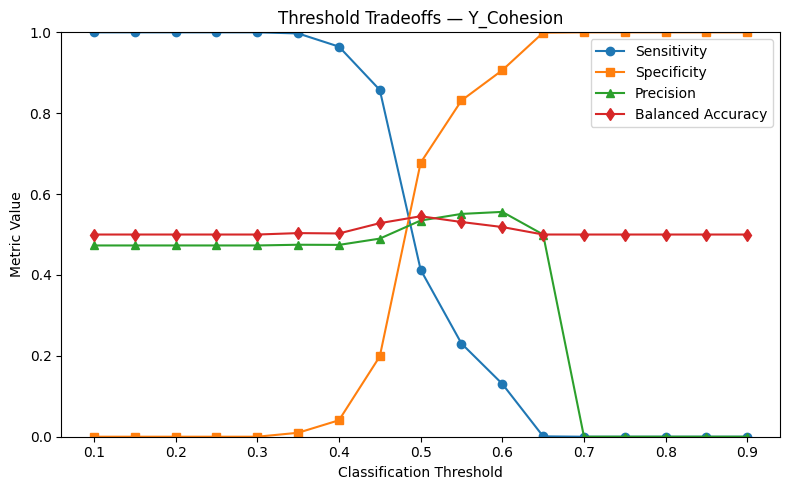

In [19]:
# Threshold Tradeoff Analysis for Deep-Dive Model
# Import
from sklearn.metrics import (precision_score,recall_score,f1_score,balanced_accuracy_score,confusion_matrix,roc_auc_score)

# Reusing the locked final fitted model when available.
if ('final_models' in globals()and DEEP_TARGET in final_models):
    final_deep_model = final_models[DEEP_TARGET]
else:
    # Fallback only if the Stage 5 cell has not retained the object.
    final_deep_model = clone(deep_pipeline)
    final_deep_model.fit(configuration_input(train_df, DEEP_FEATURE_SET),train_df[DEEP_TARGET].astype(int))

X_holdout_deep = configuration_input(holdout_df,DEEP_FEATURE_SET)
y_holdout_deep = (holdout_df[DEEP_TARGET].astype(int).to_numpy())
holdout_probability = (final_deep_model.predict_proba(X_holdout_deep)[:, 1])

print('Deep-dive holdout ROC-AUC:',round(roc_auc_score(y_holdout_deep,holdout_probability),4))

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    prediction = (holdout_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_holdout_deep,prediction,labels=[0, 1]).ravel()
    sensitivity = (tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan)
    specificity = (tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan)
    threshold_rows.append({'threshold': threshold,'precision': precision_score(y_holdout_deep,prediction,zero_division=0),
        'sensitivity_recall': sensitivity,
        'specificity': specificity,
        'f1': f1_score(y_holdout_deep,prediction,zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_holdout_deep,prediction),
        'predicted_disagreement_rate': prediction.mean(),
        'TP': tp,'FP': fp,'FN': fn,'TN': tn})
threshold_tradeoffs = pd.DataFrame(threshold_rows)

print('=' * 70)
print('Threshold Tradeoffs — Descriptive Holdout Analysis')
print('=' * 70)
display(threshold_tradeoffs.round(3))

threshold_tradeoffs.to_csv(RESULTS_DIR / 'final_report_threshold_tradeoffs.csv',index=False)

# Plot: same neutral grayscale style used elsewhere in report
plt.figure(figsize=(8, 5))
plt.plot(threshold_tradeoffs['threshold'],threshold_tradeoffs['sensitivity_recall'],marker='o',label='Sensitivity')
plt.plot(threshold_tradeoffs['threshold'],threshold_tradeoffs['specificity'],marker='s',label='Specificity')
plt.plot(threshold_tradeoffs['threshold'],threshold_tradeoffs['precision'],marker='^',label='Precision')
plt.plot(threshold_tradeoffs['threshold'],threshold_tradeoffs['balanced_accuracy'],marker='d',label='Balanced Accuracy')
plt.xlabel('Classification Threshold')
plt.ylabel('Metric Value')
plt.title(f'Threshold Tradeoffs — {DEEP_TARGET}')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

tradeoff_plot = (RESULTS_DIR / 'final_report_threshold_tradeoffs.png')
plt.savefig(tradeoff_plot,dpi=300,bbox_inches='tight')
plt.show()

### Part A2 Stage 5: Failure Analysis for Three Specific Holdout Records
- The next cell selects three qualitatively different errors for the deep-dive Evaluation:
    1. **False negative:** the model strongly predicts agreement although the two ratings disagree.
    2. **False positive:** the model strongly predicts disagreement although the ratings agree.
    3. **Rare-pair or borderline error:** an additional error associated with the least-represented training rater pair when possible.
- The output includes the original row index, predicted probability, rater pair and its training frequency, prompt/background/linguistic variables, the two raw human scores for the target dimension, and a short essay excerpt when available.
- These record-level characteristics are **diagnostic clues, not causal explanations**.

In [20]:
# Failure Analysis: Three Specific Holdout Records
    # Determining the scoring dimension from the target name
deep_dimension = DEEP_TARGET.replace('Y_', '')
failure_df = holdout_df.copy()
failure_df['original_row_index'] = failure_df.index
failure_df['pred_probability'] = holdout_probability
failure_df['predicted_class'] = (failure_df['pred_probability'] >= 0.50).astype(int)
failure_df['actual_class'] = (failure_df[DEEP_TARGET].astype(int))
failure_df['prediction_correct'] = (failure_df['actual_class'] == failure_df['predicted_class'])
failure_df['failure_type'] = np.select([((failure_df['actual_class'] == 1)&(failure_df['predicted_class'] == 0)),
        ((failure_df['actual_class'] == 0)&(failure_df['predicted_class'] == 1))],['False Negative','False Positive'],default='Correct')
failure_df['distance_from_0.50'] = (failure_df['pred_probability'] - 0.50).abs()

# Training frequency of each UNORDERED rater pair
def make_pair_key(data):
    r1 = (data['Rater_1'].fillna('__MISSING__').astype(str))
    r2 = (data['Rater_2'].fillna('__MISSING__').astype(str))
    return pd.Series(['||'.join(sorted([a, b])) for a, b in zip(r1, r2)],index=data.index,name='rater_pair')
train_pair_key = make_pair_key(train_df)
holdout_pair_key = make_pair_key(failure_df)
pair_frequency = train_pair_key.value_counts()
failure_df['rater_pair'] = holdout_pair_key
failure_df['rater_pair_train_n'] = (failure_df['rater_pair'].map(pair_frequency).fillna(0).astype(int))

# Optional diagnostic for unusually short/long essays.
if 'num_words' in train_df.columns:
    low_word_cut = train_df['num_words'].quantile(0.05)
    high_word_cut = train_df['num_words'].quantile(0.95)
    failure_df['extreme_length'] = ((failure_df['num_words'] < low_word_cut)|(failure_df['num_words'] > high_word_cut))

# Failure category 1: most-confident false negative
false_negatives = (failure_df[failure_df['failure_type'] == 'False Negative'].sort_values('pred_probability', ascending=True))
# Failure category 2: most-confident false positive
false_positives = (failure_df[failure_df['failure_type'] == 'False Positive'].sort_values('pred_probability', ascending=False))
# Failure category 3 candidates: all remaining errors
all_errors = (failure_df[failure_df['prediction_correct'] == False].copy())
selected_failures = []
if len(false_negatives) > 0:
    fn_case = false_negatives.iloc[[0]].copy()
    fn_case['analysis_category'] = ('False negative')
    selected_failures.append(fn_case)
if len(false_positives) > 0:
    fp_case = false_positives.iloc[[0]].copy()
    fp_case['analysis_category'] = ('False positive')
    selected_failures.append(fp_case)

already_selected = set()
for temp in selected_failures:
    already_selected.update(temp['original_row_index'].tolist())
remaining_errors = all_errors[~all_errors['original_row_index'].isin(already_selected)].copy()
# Prefer an error from the least-represented training rater pair.
if len(remaining_errors) > 0:
    third_case = (remaining_errors.sort_values(['rater_pair_train_n', 'distance_from_0.50'],ascending=[True, False]).iloc[[0]].copy())
    third_case['analysis_category'] = ('Low-frequency rater-pair error')
    selected_failures.append(third_case)

# Fallback: if fewer than three cases were obtained, add the
# remaining misclassification nearest the 0.50 boundary.
if len(selected_failures) < 3:
    already_selected = set()
    for temp in selected_failures:
        already_selected.update(temp['original_row_index'].tolist())
    fallback = (all_errors[~all_errors['original_row_index'].isin(already_selected)].sort_values('distance_from_0.50'))
    if len(fallback) > 0:
        borderline_case = fallback.iloc[[0]].copy()
        borderline_case['analysis_category'] = ('Borderline misclassification')
        selected_failures.append(borderline_case)
if len(selected_failures) == 0:
    raise ValueError('No holdout prediction failures were found for the deep-dive model.')
failure_examples = pd.concat(selected_failures[:3],ignore_index=True)

# Reporting columns
candidate_id_columns = ['essay_id','Essay_ID','response_id','Response_ID','id','ID']
id_columns = [c for c in candidate_id_columns if c in failure_examples.columns]
score_columns = [f'{deep_dimension}_1',f'{deep_dimension}_2',f'Delta_{deep_dimension}',DEEP_TARGET]
base_diagnostic_columns = ['analysis_category','original_row_index','failure_type','actual_class','predicted_class','pred_probability',
    'rater_pair','rater_pair_train_n','prompt','grade','gender','race_ethnicity','SES','num_words','num_sent','num_para','MTLD','TTR','extreme_length']
report_columns = (id_columns + base_diagnostic_columns + score_columns)
report_columns = [c for c in report_columns if c in failure_examples.columns]
failure_report = failure_examples[report_columns].copy()
# Add a short essay excerpt when the text column is present.
if ('TEXT_COL' in globals() and TEXT_COL in failure_examples.columns):
    failure_report['essay_excerpt'] = (failure_examples[TEXT_COL].fillna('').astype(str).str[:500])

print('=' * 70)
print('Example: Three Specific Holdout Failures')
print('=' * 70)

#Displaying the results
display(failure_report)

# Saving failure analysis 
output_file = RESULTS_DIR / 'final_report_three_failure_examples.csv'
failure_report.to_csv(output_file,index=False)
print(f"Saved to: {output_file}")

Example: Three Specific Holdout Failures


,analysis_category,original_row_index,failure_type,actual_class,predicted_class,pred_probability,rater_pair,rater_pair_train_n,prompt,grade,...,num_sent,num_para,MTLD,TTR,extreme_length,Cohesion_1,Cohesion_2,Delta_Cohesion,Y_Cohesion,essay_excerpt
0,False negative,4380,False Negative,1,0,0.330067,rater_4||rater_6,19,Distance learning,12,...,16,5,35.275638,38.314176,False,3,4,1,1,Students wouldn't benefit from attending class...
1,False positive,3790,False Positive,0,1,0.653623,rater_23||rater_9,11,Impact of technology,11,...,17,4,45.392179,40.684411,False,3,3,0,0,"Technology, has been discuess by many knowledg..."
2,Low-frequency rater-pair error,4310,False Negative,1,0,0.456996,rater_16||rater_20,3,Creative arts requirement,12,...,31,8,51.365275,32.189542,True,3,4,1,1,Would you like to have an art class as an elec...


Saved to: C:\Users\USEO9DA\0_MyStuff\M2\results\final_report_three_failure_examples.csv


# End of Supervised Analysis